## Imports

In [1]:
from eval import tracs_rate_scenario, compute_argoverse2_metrics
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from os import makedirs
from json import dump

## Load data

In [2]:
data_root = Path("../dataset")
backbone = "DeMo"
number_of_tests = 10
prediction_path = data_root / f"{backbone}_submission.parquet"
backbone_metrics_path = data_root / f"{backbone}_metrics.parquet"
results_path = data_root / "results" / backbone

## Logic to test

In [3]:
logic = """
distance(vehicle) <- source("/star_map/distance/vehicle", Density).
speed <- source("/sensors/speed", Number).

landscape if distance(vehicle) > 5 and speed < 50.

landscape -> target("/landscape").
"""

tracs_metrics_path = results_path / str(hash(logic)) / "metrics.parquet"
gt_scores_path = results_path / str(hash(logic)) / "gt_scores.parquet"
makedirs(results_path / str(hash(logic)), exist_ok=True)

## Run tests

In [4]:
backbone_metrics_df = pd.read_parquet(backbone_metrics_path)

tracs_metrics = []
tracs_gt_scores = []
for i in np.random.choice(range(len(backbone_metrics_df)), size=number_of_tests, replace=False):
    scenario_id = backbone_metrics_df.iloc[i]["scenario_id"]
    scored_predictions, gt_score = tracs_rate_scenario(
        scenario_id=scenario_id,
        logic=logic,
        prediction_path=prediction_path,
        data_root=data_root,
        mode="test",
    )
    
    tracs_metrics.append(compute_argoverse2_metrics(scored_predictions, data_root, scenario_id))
    tracs_gt_scores.append(pd.DataFrame({"scenario_id": [scenario_id], "tracs_trajectory_score": [gt_score]}))

tracs_metrics = pd.concat(tracs_metrics)
tracs_gt_scores = pd.concat(tracs_gt_scores)
with open(results_path / str(hash(logic)) / "tracs_test.json", "w") as file:
    dump({"logic": logic, "metrics_path": str(tracs_metrics_path.absolute), "gt_scores_path": str(gt_scores_path.absolute)}, file)

tracs_metrics.to_parquet(tracs_metrics_path)
tracs_gt_scores.to_parquet(gt_scores_path)

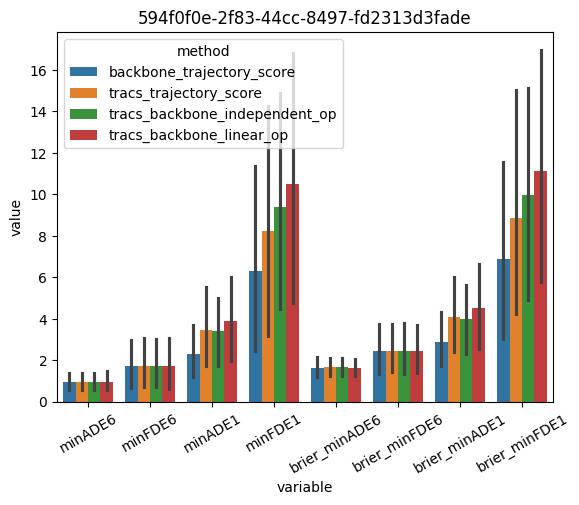

In [5]:
melted = tracs_metrics.melt("method")
melted = melted[melted["variable"] != "scenario_id"]
melted = melted[melted["variable"] != "track_id"]
melted = melted[melted["variable"] != "is_missed_prediction6"]
melted = melted[melted["variable"] != "is_missed_prediction1"]

plt.title(f"{scenario_id}")
sns.barplot(melted, x="variable", y="value", hue="method")
plt.xticks(rotation=30)
plt.show()

In [6]:
tracs_gt_scores["tracs_trajectory_score"].mean()

np.float64(0.45392530903804396)